# Evaluación del modelo toy


### 1. Definir toy model simple

In [1]:
import cobra


def modelo_toy_simple():
    """
    Modelo toy con tres especies metabólicamente complementarias.

    B1: auxótrofo de glutamato, consume glucosa.
    B2: especialista en acetato.
    B3: especialista en succinato.

    Cada especie tiene una fuente de carbono preferente
    y se restringe el consumo de las fuentes asignadas
    a las otras especies.
    """

    base = cobra.io.load_model("textbook")

    B1 = base.copy()
    B2 = base.copy()
    B3 = base.copy()

    # --------------------------------------------------
    # B1: consumidor de glucosa, auxótrofo de glutamato
    # --------------------------------------------------

    B1.reactions.get_by_id("GLUDy").bounds = (0, 0)
    B1.reactions.get_by_id("GLUSy").bounds = (0, 0)

    # Evitar consumo de acetato y succinato
    B1.reactions.get_by_id("ACt2r").bounds = (0, 0)
    B1.reactions.get_by_id("SUCCt2_2").bounds = (0, 0)

    # --------------------------------------------------
    # B2: especialista en acetato
    # --------------------------------------------------

    B2.reactions.get_by_id("GLCpts").bounds = (0, 0)
    B2.reactions.get_by_id("SUCCt2_2").bounds = (0, 0)

    # --------------------------------------------------
    # B3: especialista en succinato
    # --------------------------------------------------

    B3.reactions.get_by_id("GLCpts").bounds = (0, 0)
    B3.reactions.get_by_id("ACt2r").bounds = (0, 0)

    modelos = {
        "B1": B1,
        "B2": B2,
        "B3": B3
    }

    return modelos


# Medio de cultivo común
medio = {
    "glc__D_e": (-10, 100),
    "ac_e": (-10, 100),
    "succ_e": (-10, 100),
    "o2_e": (-15, 100),
    "glu__L_e": (-10, 100),
    "nh4_e": (-100, 100),
    "pi_e": (-100, 100),
    "h2o_e": (-100, 100),
    "h_e": (-100, 100),
    "co2_e": (-100, 100)
}

medios_individuales = {
    "B1": medio.copy(),
    "B2": medio.copy(),
    "B3": medio.copy()
}

### 2. Implementar metodo

In [2]:
# Importaciones necesarias
import importlib
import metodo.community_moma as cm
importlib.reload(cm)
import metodo.results as results
importlib.reload(results)
from metodo.referencias import calcular_referencias, imprimir_referencias
import numpy as np
import pandas as pd

In [3]:
# Evaluar referencias
modelos = modelo_toy_simple()
referencias = calcular_referencias(modelos, medio, medios_individuales)
imprimir_referencias(referencias)

Set parameter Username
Set parameter LicenseID to value 2854514
Academic license - for non-commercial use only - expires 2027-08-19
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpoo056l7j.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmp61kfh05e.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpym7pqm7k.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmpjkaocp5x.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3xn900000gn/T/tmptcqdtjbj.lp
Reading time = 0.00 seconds
: 72 rows, 190 columns, 720 nonzeros
Read LP format model from file /var/folders/s0/4ql9zp392d588l6dcrm3x

In [4]:
# Barrido de crecimiento (Community MOMA) para diferentes valores de alpha
alphas = np.linspace(0.5, 1.0, 11)

resultados = cm.barrido_moma(
    referencias=referencias,
    medio=medio,
    alphas=alphas,
    residentes=["B1", "B2"],
    invasores=["B3"],
    pesos="norma",
    coexistencia=True
)

Set parameter NonConvex to value 2
Set parameter OptimalityTarget to value 1
Set parameter TimeLimit to value 600
mu=0.424946 | status=18 | soluciones=2 | objetivo=1.093523
alpha=0.50 | mu=0.424946 | status=18 | 
mu=0.467440 | status=18 | soluciones=1 | objetivo=0.721657
alpha=0.55 | mu=0.467440 | status=18 | 
mu=0.509935 | status=7 | soluciones=2 | objetivo=0.620472
alpha=0.60 | mu=0.509935 | status=7 | 
mu=0.552430 | status=7 | soluciones=2 | objetivo=1.118047
alpha=0.65 | mu=0.552430 | status=7 | 
mu=0.594924 | status=7 | soluciones=2 | objetivo=2.236444
alpha=0.70 | mu=0.594924 | status=7 | 
mu=0.637419 | status=7 | soluciones=2 | objetivo=3.955093
alpha=0.75 | mu=0.637419 | status=7 | 
mu=0.679913 | status=7 | soluciones=2 | objetivo=6.256008
alpha=0.80 | mu=0.679913 | status=7 | 
mu=0.722408 | status=7 | soluciones=2 | objetivo=9.203515
alpha=0.85 | mu=0.722408 | status=7 | 
mu=0.764902 | status=18 | soluciones=1 | objetivo=13.721243
alpha=0.90 | mu=0.764902 | status=18 | 
mu=0.8

### 3. Resultados


(<Figure size 1000x500 with 1 Axes>,
 <Axes: title={'center': 'Abundancias: referencias vs Community MOMA'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Abundancia relativa'>)

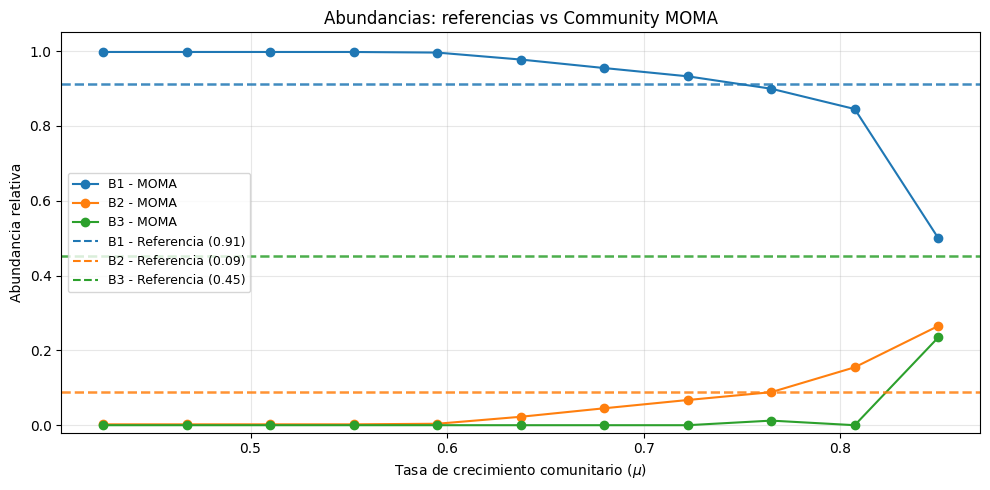

In [5]:
results.graficar_abundancias(resultados)

In [6]:
results.imprimir_resumen(resultados)

COMPARACIÓN STEADYCOM vs COMMUNITY MOMA
Mu máximo SteadyCom reportado : 0.849892
Mu techo con coexistencia     : 0.849892

Abundancias de referencia SteadyCom:
  B1: 0.499757
  B2: 0.048061
  B3: 0.452182

Abundancias de referencia de residentes:
  B1: 0.912268
  B2: 0.087732

Resumen de resoluciones:
  Resoluciones ejecutadas : 11
  Soluciones factibles    : 11
  Sin solución factible   : 0

Mayor mu MOMA factible en el barrido: 0.849892
Alpha correspondiente              : 1.000000
Costo total correspondiente         : 150.275679
Estado de optimización               : 18


,alpha,mu,status,factible,objetivo,cost_residentes,cost_invasores,cost_total,tiempo,B1_MOMA,B1_Referencia,B2_MOMA,B2_Referencia,B3_MOMA,B3_Referencia
0,0.50,0.424946,18,True,1.093523,1.032212,0.061311,1.093523,None,0.997513,0.912268,0.002387,0.087732,0.000100,0.452182
1,0.55,0.467440,18,True,0.721657,0.720369,0.001288,0.721657,None,0.997516,0.912268,0.002384,0.087732,0.000100,0.452182
2,0.60,0.509935,7,True,0.620472,0.467703,0.152769,0.620472,None,0.997498,0.912268,0.002402,0.087732,0.000100,0.452182
3,0.65,0.552430,7,True,1.118047,0.273749,0.844298,1.118047,None,0.997469,0.912268,0.002423,0.087732,0.000108,0.452182
4,0.70,0.594924,7,True,2.236444,0.139036,2.097409,2.236444,None,0.995919,0.912268,0.003981,0.087732,0.000100,0.452182
5,0.75,0.637419,7,True,3.955093,0.056264,3.898829,3.955093,None,0.977313,0.912268,0.022587,0.087732,0.000100,0.452182
6,0.80,0.679913,7,True,6.256008,0.010823,6.245186,6.256008,None,0.954586,0.912268,0.045314,0.087732,0.000100,0.452182
7,0.85,0.722408,7,True,9.203515,0.025563,9.177953,9.203515,None,0.932478,0.912268,0.067422,0.087732,0.000100,0.452182
8,0.90,0.764902,18,True,13.721243,0.752846,12.968397,13.721243,None,0.899293,0.912268,0.088365,0.087732,0.012342,0.452182
9,0.95,0.807397,7,True,22.040319,5.388334,16.651985,22.040319,None,0.845033,0.912268,0.154867,0.087732,0.000100,0.452182


(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Costo metabólico vs. crecimiento comunitario'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Costo metabólico (función objetivo)'>)

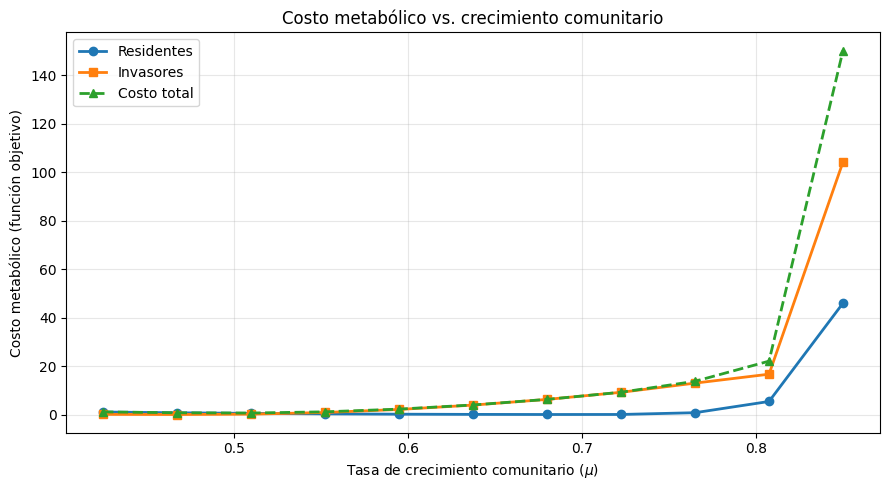

In [7]:
results.graficar_costo_metabolico(resultados)

Set parameter NonConvex to value 2
Set parameter OptimalityTarget to value 1
Set parameter TimeLimit to value 600
mu=0.424946 | status=7 | soluciones=2 | objetivo=1.721998
alpha=0.50 | mu=0.424946 | status=7 | 
mu=0.467440 | status=18 | soluciones=1 | objetivo=1.171225
alpha=0.55 | mu=0.467440 | status=18 | 
mu=0.509935 | status=7 | soluciones=2 | objetivo=1.064718
alpha=0.60 | mu=0.509935 | status=7 | 
mu=0.552430 | status=7 | soluciones=2 | objetivo=1.918082
alpha=0.65 | mu=0.552430 | status=7 | 
mu=0.594924 | status=7 | soluciones=2 | objetivo=3.809223
alpha=0.70 | mu=0.594924 | status=7 | 
mu=0.637419 | status=7 | soluciones=2 | objetivo=6.718626
alpha=0.75 | mu=0.637419 | status=7 | 
mu=0.679913 | status=7 | soluciones=2 | objetivo=10.698862
alpha=0.80 | mu=0.679913 | status=7 | 
mu=0.722408 | status=7 | soluciones=2 | objetivo=15.759015
alpha=0.85 | mu=0.722408 | status=7 | 
mu=0.764902 | status=7 | soluciones=2 | objetivo=24.641594
alpha=0.90 | mu=0.764902 | status=7 | 
mu=0.807

(<Figure size 900x500 with 1 Axes>,
 <Axes: title={'center': 'Costo metabólico vs. crecimiento comunitario'}, xlabel='Tasa de crecimiento comunitario ($\\mu$)', ylabel='Costo metabólico (función objetivo)'>)

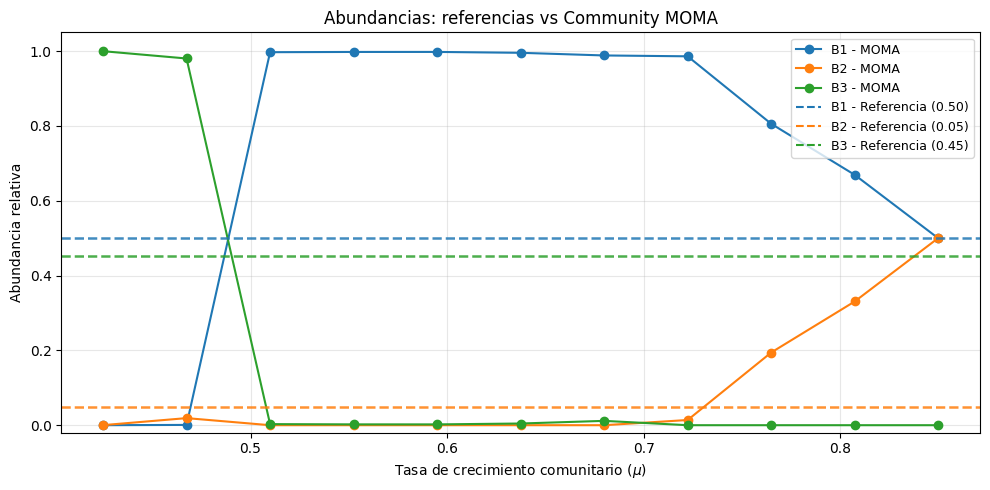

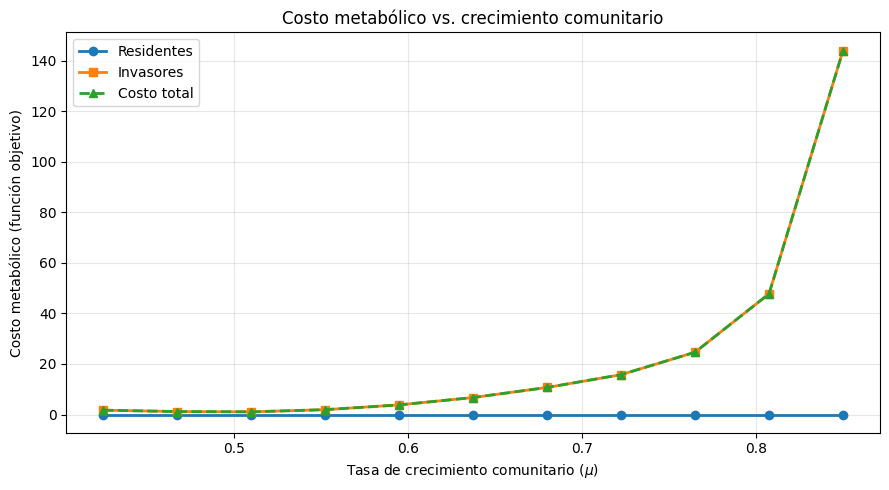

In [8]:
# Caso sin residentes, 3 invasores
resultados_sin_residentes = cm.barrido_moma(
    referencias=referencias,
    medio=medio,
    alphas=np.linspace(0.5, 1.0, 11),
    residentes=[],
    invasores=["B1", "B2", "B3"],
    coexistencia=True
)

results.graficar_abundancias(resultados_sin_residentes)
results.imprimir_resumen(resultados_sin_residentes)
results.graficar_costo_metabolico(resultados_sin_residentes)